# Predicting house sale prices in King County (Seattle area)

**Team 7:** Ugo, Alvaro, Sneha
**Course:** AI Methods I – Day 2: Supervised learning (IAAC MaAI 2026/27)

## 0. Introduction and problem definition

**Use case.** A real estate agent or small investor scouting houses to buy in King County wants a quick, data-based estimate of what a house is worth, from the facts listed on a sales sheet (size, rooms, quality grade, condition, location). The estimate is compared with the asking price to spot good deals.

**Which mistake is costly?** *Under-estimating* the value. If the model says a house is worth less than it really is, the agent dismisses a good property and misses the deal. Over-estimating also costs money, so we optimise the average error but always check in which direction the model is wrong.

**Problem type:** regression. **Target:** `price` (sale price in US dollars).

**Main metric: MAE (mean absolute error, in $).** It is in the same unit as the price and easy to explain to a client ("on average the estimate is off by $X"). We also report RMSE (punishes large errors), R² (share of variance explained) and MAPE (error in %, fairer across cheap and expensive houses).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import train_test_split, KFold, cross_validate, validation_curve, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import (mean_absolute_error, root_mean_squared_error, r2_score,
                             mean_absolute_percentage_error)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "figures"
MODEL_DIR = Path("..") / "models"
FIG_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


### 0.1 Load the cleaned data

We load the cleaned dataset saved at the end of `data_cleaning_and_EDA.ipynb`. In that notebook we removed 18 impossible rows (more than 10 bedrooms, 0 bedrooms or 0 bathrooms). We **kept** the expensive houses: the EDA showed they follow the same size–price trend as the rest, so they are real, not errors.

`zipcode` and `id` are read as text, so pandas does not treat them as numbers.

In [2]:
df = pd.read_csv(DATA_DIR / "housing_clean.csv", dtype={"zipcode": str, "id": str})
df["date"] = pd.to_datetime(df["date"])
print(df.shape)
df.head()

(21595, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7229300521,2014-10-13,"231,300.000",2,1.000,1180,5650,1.000,0,0,...,7,1180,0,1955,0,98178,47.511,-122.257,1340,5650
1,6414100192,2014-12-09,"538,000.000",3,2.250,2570,7242,2.000,0,0,...,7,2170,400,1951,1991,98125,47.721,-122.319,1690,7639
2,5631500400,2015-02-25,"180,000.000",2,1.000,770,10000,1.000,0,0,...,6,770,0,1933,0,98028,47.738,-122.233,2720,8062
3,2487200875,2014-12-09,"604,000.000",4,3.000,1960,5000,1.000,0,0,...,7,1050,910,1965,0,98136,47.521,-122.393,1360,5000
4,1954400510,2015-02-18,"510,000.000",3,2.000,1680,8080,1.000,0,0,...,8,1680,0,1987,0,98074,47.617,-122.045,1800,7503


## 1. Features, leakage and split

### 1.1 One row per house

Some houses were sold twice in 2014–15 (same `id`). If one sale ends up in the training set and the other in the test set, the model has already "seen" the house and the test score is too optimistic. We keep only the **most recent sale** of each house: that is the price an agent cares about.

In [3]:
n_before = len(df)
df = df.sort_values("date").drop_duplicates(subset="id", keep="last").reset_index(drop=True)
print(f"Removed {n_before - len(df)} earlier sales of the same house -> {len(df):,} houses")

Removed 177 earlier sales of the same house -> 21,418 houses


### 1.2 Feature engineering

Two simple features, computed row by row (they use no information from other rows or from the price, so they cannot leak):

* `renovated`: 1 if the house was ever renovated. In the raw data `yr_renovated = 0` means "never renovated", not the year 0, so the raw column would mislead a linear model.
* `size_vs_neighbours`: living area divided by the average living area of the 15 nearest houses (`sqft_living15`). From the EDA: is it worth being the biggest house on the street?

In [4]:
df["renovated"] = (df["yr_renovated"] > 0).astype(int)
df["size_vs_neighbours"] = df["sqft_living"] / df["sqft_living15"]
df[["renovated", "size_vs_neighbours"]].describe().T

,count,mean,std,min,25%,50%,75%,max
renovated,"21,418.000",0.042,0.202,0.000,0.000,0.000,0.000,1.000
size_vs_neighbours,"21,418.000",1.054,0.320,0.187,0.882,1.000,1.162,6.000


### 1.3 Define X and y

| Removed column | Why |
|---|---|
| `price` | the target |
| `id` | an identifier, no meaning for the price |
| `date` | the sale date: all sales are from one year (May 2014 – May 2015), and an agent wants a value *now*, not tied to a past sale date |
| `sqft_above` | redundant: `sqft_above + sqft_basement = sqft_living` exactly |
| `yr_renovated` | replaced by the clearer `renovated` flag |
| any column built from the price (e.g. `price_per_sqft`, `log_price` from the EDA) | **leakage**: the price would be hidden inside the inputs |

Everything we keep is printed on a normal sales sheet, so the agent knows it at prediction time. Because the model values **existing** houses, `condition` (state of maintenance) and `renovated` are fair inputs.

In [5]:
print("sqft_above + sqft_basement == sqft_living for every row:",
      (df["sqft_above"] + df["sqft_basement"] == df["sqft_living"]).all())

TARGET = "price"
NUMERIC = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors", "sqft_basement",
           "yr_built", "lat", "long", "sqft_living15", "sqft_lot15", "size_vs_neighbours"]
ORDINAL = ["grade", "condition", "view"]
NOMINAL = ["zipcode"]
BINARY = ["waterfront", "renovated"]
FEATURES = NUMERIC + ORDINAL + NOMINAL + BINARY

X = df[FEATURES]
y = df[TARGET]
print(X.shape, "features:", len(FEATURES))

sqft_above + sqft_basement == sqft_living for every row: True
(21418, 18) features: 18


### 1.4 Log of the target

The price is strongly right-skewed: most houses cost $300–650K, a few cost several million (see the boxplot in the EDA). If we train on the raw price, the few expensive houses dominate the squared errors, and a linear model fits a straight line to a relationship that is really multiplicative (an extra 100 sqft adds more value to a big house in an expensive area than to a small one).

We therefore train the models on **log(price)**. We use `TransformedTargetRegressor`: the model learns log(price) and its predictions are converted back with `exp`, so every metric below is still in dollars.

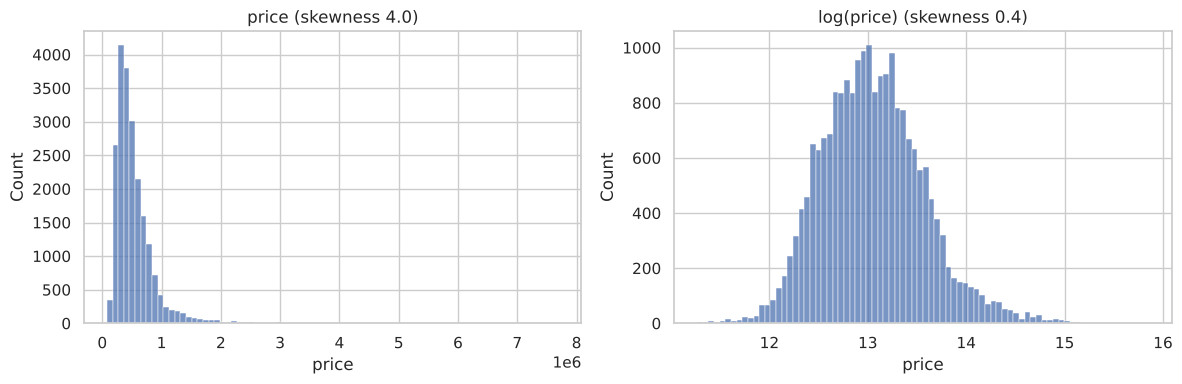

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y, bins=80, ax=axes[0]); axes[0].set_title(f"price (skewness {y.skew():.1f})")
sns.histplot(np.log(y), bins=80, ax=axes[1]); axes[1].set_title(f"log(price) (skewness {np.log(y).skew():.1f})")
plt.tight_layout(); plt.show()

### 1.5 Train / test split

80 % training, 20 % test, with a fixed `random_state`. The test set is **locked** until section 5: every decision (features, model, hyperparameters) is made with cross-validation on the training set only.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"train: {len(X_train):,} houses   test: {len(X_test):,} houses")
print(f"median price  train: ${y_train.median():,.0f}   test: ${y_test.median():,.0f}")

train: 17,134 houses   test: 4,284 houses
median price  train: $452,000   test: $450,000


## 2. Preprocessing pipeline

All preprocessing lives inside a scikit-learn `Pipeline`, so during cross-validation it is fitted on the training folds only (no leakage from the validation fold).

| Columns | Steps | Why |
|---|---|---|
| Numeric (sizes, rooms, year built, lat/long, …) | median imputation + `StandardScaler` | no missing values today, but the imputer protects the saved model against incomplete input. Scaling is needed for Ridge and KNN (distances, penalties); trees ignore it. |
| `grade` (1–13), `condition` (1–5), `view` (0–4) | `OrdinalEncoder` with an **explicit order** + scaling | ordinal categories stored as numbers: the order matters (grade 10 is better than grade 7) so we keep it, and we write the order down so an unseen value can't silently get the wrong code |
| `zipcode` | `OneHotEncoder(handle_unknown="ignore")` | a **nominal category stored as a number**: zipcode 98199 is not "bigger" than 98001. Treating it as a number would be meaningless. One column per zipcode (70). |
| `waterfront`, `renovated` | passthrough | already 0/1 |

In [8]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

ordinal_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OrdinalEncoder(
        categories=[list(range(1, 14)),   # grade: 1 (poor) ... 13 (mansion quality)
                    list(range(1, 6)),    # condition: 1 (poor) ... 5 (very good)
                    list(range(0, 5))],   # view: 0 (none) ... 4 (excellent)
        handle_unknown="use_encoded_value", unknown_value=-1)),
    ("scale", StandardScaler()),
])

nominal_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, NUMERIC),
    ("ord", ordinal_pipe, ORDINAL),
    ("nom", nominal_pipe, NOMINAL),
    ("bin", "passthrough", BINARY),
])


def make_pipeline(regressor):
    """Preprocessing + a regressor trained on log(price), predicting in dollars."""
    return Pipeline([
        ("prep", preprocessor),
        ("model", TransformedTargetRegressor(regressor=regressor, func=np.log, inverse_func=np.exp)),
    ])


# check: how many columns come out of the preprocessing?
n_out = preprocessor.fit(X_train).transform(X_train.head()).shape[1]
print("columns after preprocessing:", n_out)

columns after preprocessing: 87


## 3. Model comparison

We compare a baseline and four model families, with **the same 5 folds** (`KFold` with a fixed seed) and the same metrics for every model, on the training set only.

| Model | Family | Why we try it |
|---|---|---|
| `DummyRegressor(median)` | baseline | predicts the median price for every house. Any useful model must beat it clearly. |
| `Ridge` | linear | simple, fast, interpretable coefficients. On log(price) each coefficient is a % effect. |
| `KNeighborsRegressor` | instance-based | "price of similar houses nearby", which is how agents value houses (comparables) |
| `RandomForestRegressor` | tree ensemble (bagging) | captures non-linear effects and interactions (e.g. size × location) |
| `HistGradientBoostingRegressor` | tree ensemble (boosting) | usually the strongest on tabular data, and fast |

In [9]:
models = {
    "Baseline (median)": DummyRegressor(strategy="median"),
    "Ridge": Ridge(alpha=1.0),
    "KNN (k=10)": KNeighborsRegressor(n_neighbors=10, weights="distance"),
    "Random forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                           n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient boosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
    "MAPE": "neg_mean_absolute_percentage_error",
}

cv_results = {}
for name, reg in models.items():
    res = cross_validate(make_pipeline(reg), X_train, y_train, cv=cv, scoring=scoring,
                         return_train_score=True, n_jobs=1)
    cv_results[name] = res
    print(f"{name:<20} MAE ${-res['test_MAE'].mean():>9,.0f} ± {res['test_MAE'].std():>7,.0f}"
          f"   R² {res['test_R2'].mean():.3f}   fit {res['fit_time'].mean():.1f}s")

Baseline (median)    MAE $  222,072 ±   4,184   R² -0.061   fit 0.1s


Ridge                MAE $   74,964 ±   1,692   R² 0.860   fit 0.1s


KNN (k=10)           MAE $   84,965 ±   2,337   R² 0.774   fit 0.1s


Random forest        MAE $   70,368 ±   1,399   R² 0.864   fit 10.1s


Gradient boosting    MAE $   65,367 ±   1,846   R² 0.887   fit 1.0s


### 3.1 Results table (mean ± standard deviation over the 5 folds)

In [10]:
rows = []
for name, res in cv_results.items():
    row = {"model": name}
    for m in scoring:
        vals = res[f"test_{m}"] * (1 if m == "R2" else -1)   # sklearn returns negative errors
        if m == "MAPE":
            vals = vals * 100
        row[f"{m} mean"] = vals.mean()
        row[f"{m} std"] = vals.std()
    row["train MAE"] = -res["train_MAE"].mean()
    row["fit time (s)"] = res["fit_time"].mean()
    rows.append(row)

results = pd.DataFrame(rows).set_index("model")

# readable version: "mean ± std"
pretty = pd.DataFrame({
    "MAE ($)": [f"{r['MAE mean']:,.0f} ± {r['MAE std']:,.0f}" for _, r in results.iterrows()],
    "RMSE ($)": [f"{r['RMSE mean']:,.0f} ± {r['RMSE std']:,.0f}" for _, r in results.iterrows()],
    "R²": [f"{r['R2 mean']:.3f} ± {r['R2 std']:.3f}" for _, r in results.iterrows()],
    "MAPE (%)": [f"{r['MAPE mean']:.1f} ± {r['MAPE std']:.1f}" for _, r in results.iterrows()],
    "train MAE ($)": [f"{v:,.0f}" for v in results["train MAE"]],
    "fit time (s)": [f"{v:.1f}" for v in results["fit time (s)"]],
}, index=results.index)
pretty

,MAE ($),RMSE ($),R²,MAPE (%),train MAE ($),fit time (s)
model,,,,,,
Baseline (median),"222,072 ± 4,184","378,509 ± 24,063",-0.061 ± 0.008,42.2 ± 0.7,"222,049",0.1
Ridge,"74,964 ± 1,692","137,588 ± 18,331",0.860 ± 0.024,13.7 ± 0.2,"74,503",0.1
KNN (k=10),"84,965 ± 2,337","175,190 ± 18,180",0.774 ± 0.019,14.6 ± 0.3,1,0.1
Random forest,"70,368 ± 1,399","135,381 ± 6,194",0.864 ± 0.009,12.6 ± 0.1,"31,059",10.1
Gradient boosting,"65,367 ± 1,846","123,631 ± 13,318",0.887 ± 0.014,12.0 ± 0.1,"55,065",1.0


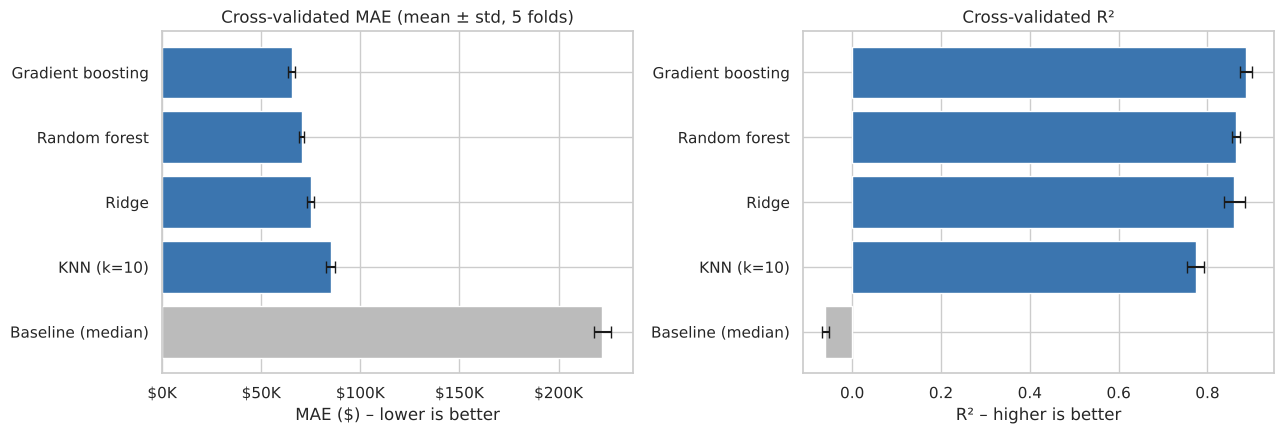

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = results.sort_values("MAE mean", ascending=False).index
colors = ["#bbbbbb" if n.startswith("Baseline") else "#3b75af" for n in order]

axes[0].barh(order, results.loc[order, "MAE mean"], xerr=results.loc[order, "MAE std"],
             color=colors, capsize=4)
axes[0].set_xlabel("MAE ($) – lower is better")
axes[0].set_title("Cross-validated MAE (mean ± std, 5 folds)")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))

axes[1].barh(order, results.loc[order, "R2 mean"], xerr=results.loc[order, "R2 std"],
             color=colors, capsize=4)
axes[1].set_xlabel("R² – higher is better")
axes[1].set_title("Cross-validated R²")
axes[1].set_xlim(left=min(0, results["R2 mean"].min() - 0.05))

plt.tight_layout()
plt.savefig(FIG_DIR / "01_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.2 Which differences are real?

* **Every model beats the baseline by far.** The baseline is off by $222K on average (R² −0.06); all real models are between $65K and $85K (R² 0.77–0.89).
* **Gradient boosting is the best: MAE $65.4K ± 1.8K.** Its gap to the random forest ($70.4K ± 1.4K) is about $5K, roughly three standard deviations, so it is a **real** difference. It is also 10× faster to train (1 s vs 10 s).
* **Random forest vs Ridge:** in MAE the forest is better ($70.4K vs $75.0K, a real gap), but in R² they are **within noise** (0.864 ± 0.009 vs 0.860 ± 0.024). Ridge does surprisingly well because predicting log(price) makes the relationship almost linear, and the one-hot zipcodes give it the location.
* **KNN is the weakest** ($85K). Its training MAE of ~$1 shows that `weights="distance"` simply memorises the training houses. Also, "nearest" in the scaled feature space is not the same as a comparable house: one extra bedroom counts as much as a big change in location.
* **The random forest overfits:** training MAE $31K vs validation $70K.
* Caveat: the 5 folds share most of their training data, so the standard deviations underestimate the real uncertainty. We treat differences smaller than about one standard deviation as noise.

## 4. Diagnosis and tuning

### 4.1 Validation curve: tree depth of gradient boosting

`max_depth` controls how complex each tree can be. Too shallow → the model can't capture interactions (underfitting). Too deep → it memorises the training data (overfitting). We compare the training and validation MAE for each depth, with the same 5 folds.

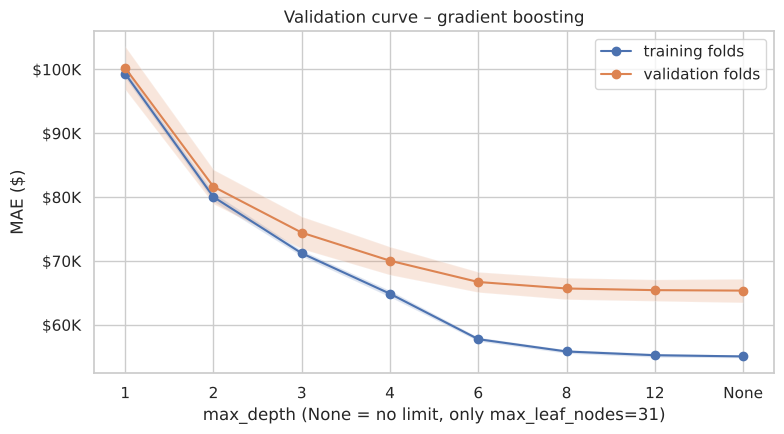

,max_depth,train MAE,validation MAE,gap
0,1,"99,321.313","100,219.448",898.135
1,2,"80,026.397","81,630.127","1,603.730"
2,3,"71,210.319","74,440.661","3,230.341"
3,4,"64,874.342","70,043.309","5,168.968"
4,6,"57,762.324","66,714.750","8,952.426"
5,8,"55,835.215","65,698.034","9,862.819"
6,12,"55,250.434","65,439.764","10,189.330"
7,None,"55,065.281","65,366.836","10,301.555"


In [12]:
depths = [1, 2, 3, 4, 6, 8, 12, None]
train_scores, val_scores = validation_curve(
    make_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
    X_train, y_train,
    param_name="model__regressor__max_depth", param_range=depths,
    cv=cv, scoring="neg_mean_absolute_error", n_jobs=1,
)
train_mae, val_mae = -train_scores, -val_scores

labels = [str(d) for d in depths]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(labels, train_mae.mean(axis=1), "o-", label="training folds")
ax.fill_between(labels, train_mae.mean(1) - train_mae.std(1), train_mae.mean(1) + train_mae.std(1), alpha=0.2)
ax.plot(labels, val_mae.mean(axis=1), "o-", label="validation folds")
ax.fill_between(labels, val_mae.mean(1) - val_mae.std(1), val_mae.mean(1) + val_mae.std(1), alpha=0.2)
ax.set_xlabel("max_depth (None = no limit, only max_leaf_nodes=31)")
ax.set_ylabel("MAE ($)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))
ax.set_title("Validation curve – gradient boosting")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "02_validation_curve.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({"max_depth": labels, "train MAE": train_mae.mean(1),
              "validation MAE": val_mae.mean(1), "gap": val_mae.mean(1) - train_mae.mean(1)})

* **Depth 1–3: underfitting.** Training and validation errors are both high and close together (depth 1, which allows no interactions between features, is off by $100K).
* **Depth 4–8:** the validation error drops to about $65.7K. Beyond 8 it is flat ($65.4K).
* The gap between training and validation grows from $0.9K to $10.3K: deeper trees fit the training houses better than new ones, so the model **overfits a little**, but the validation error never gets worse. Gradient boosting already limits each tree with `max_leaf_nodes=31` and early stopping, so the depth limit hardly matters above 8. We keep the default (no depth limit).

### 4.2 Grid search on gradient boosting

We tune the three hyperparameters that matter most for boosting: the learning rate, the number of boosting iterations, and the size of each tree (`max_leaf_nodes`). Same 5 folds, MAE as the selection metric.

In [13]:
param_grid = {
    "model__regressor__learning_rate": [0.05, 0.1],
    "model__regressor__max_iter": [300, 800],
    "model__regressor__max_leaf_nodes": [15, 31, 63],
}
grid = GridSearchCV(
    make_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
    param_grid, cv=cv, scoring="neg_mean_absolute_error", n_jobs=1, return_train_score=True,
)
grid.fit(X_train, y_train)

grid_table = (pd.DataFrame(grid.cv_results_)
              .assign(val_MAE=lambda d: -d["mean_test_score"],
                      val_MAE_std=lambda d: d["std_test_score"],
                      train_MAE=lambda d: -d["mean_train_score"],
                      fit_s=lambda d: d["mean_fit_time"])
              [["param_model__regressor__learning_rate", "param_model__regressor__max_iter",
                "param_model__regressor__max_leaf_nodes", "val_MAE", "val_MAE_std", "train_MAE", "fit_s"]]
              .sort_values("val_MAE"))
grid_table.columns = ["learning_rate", "max_iter", "max_leaf_nodes", "val MAE", "val MAE std", "train MAE", "fit time (s)"]

default_mae = results.loc["Gradient boosting", "MAE mean"]
print("Best parameters:", grid.best_params_)
print(f"Default gradient boosting  CV MAE: ${default_mae:,.0f}")
print(f"Tuned gradient boosting    CV MAE: ${-grid.best_score_:,.0f}  "
      f"(gain ${default_mae + grid.best_score_:,.0f}, {100*(default_mae + grid.best_score_)/default_mae:.1f} %)")
grid_table.head(8)

Best parameters: {'model__regressor__learning_rate': 0.05, 'model__regressor__max_iter': 800, 'model__regressor__max_leaf_nodes': 31}
Default gradient boosting  CV MAE: $65,367
Tuned gradient boosting    CV MAE: $64,011  (gain $1,356, 2.1 %)


,learning_rate,max_iter,max_leaf_nodes,val MAE,val MAE std,train MAE,fit time (s)
4,0.050,800,31,"64,010.551","1,553.208","50,340.080",2.537
1,0.050,300,31,"64,130.391","1,630.946","51,177.381",2.569
5,0.050,800,63,"64,322.035","1,593.646","46,916.894",2.886
2,0.050,300,63,"64,322.035","1,593.646","46,916.894",2.803
11,0.100,800,63,"64,501.587","1,222.835","46,337.900",1.483
8,0.100,300,63,"64,501.587","1,222.835","46,337.900",1.426
7,0.100,300,31,"64,516.563","1,563.193","50,330.706",1.349
10,0.100,800,31,"64,516.563","1,563.193","50,330.706",1.439


* The best combination (learning rate 0.05, 31 leaves, up to 800 iterations) reaches **$64.0K vs $65.4K** for the default: a gain of $1.4K (2 %). That is **smaller than one fold's standard deviation** ($1.6K), so it is within noise.
* 300 and 800 iterations give almost the same result because early stopping (on by default above 10,000 rows) stops training before either limit.
* **Is it worth it?** The gain is marginal but costs nothing at prediction time (training takes ~3 s), so we keep the tuned model. More tuning is not worth it: the remaining errors come from the data (few luxury and waterfront houses, see section 5), not from the hyperparameters.

## 5. Final evaluation on the test set (once!)

All choices are now made. We retrain the chosen pipeline (tuned gradient boosting) on the **full training set** and evaluate it **once** on the 20 % test set that has been locked since section 1.

In [14]:
final_model = grid.best_estimator_          # already refitted on the full training set by GridSearchCV
y_pred = final_model.predict(X_test)

test_scores = {
    "MAE ($)": mean_absolute_error(y_test, y_pred),
    "RMSE ($)": root_mean_squared_error(y_test, y_pred),
    "R²": r2_score(y_test, y_pred),
    "MAPE (%)": 100 * mean_absolute_percentage_error(y_test, y_pred),
    "median abs. error ($)": np.median(np.abs(y_test - y_pred)),
}
best_idx = grid.best_index_
cv_scores = {
    "MAE ($)": -grid.cv_results_["mean_test_score"][best_idx],
}
summary = pd.DataFrame({"test set": test_scores})
summary.loc["MAE ($)", "cross-validation"] = cv_scores["MAE ($)"]
summary.loc["MAE ($)", "baseline (CV)"] = results.loc["Baseline (median)", "MAE mean"]
summary.loc["R²", "baseline (CV)"] = results.loc["Baseline (median)", "R2 mean"]
summary

,test set,cross-validation,baseline (CV)
MAE ($),"62,184.551","64,010.551","222,072.335"
RMSE ($),"108,202.246",NaN,NaN
R²,0.911,NaN,-0.061
MAPE (%),11.635,NaN,NaN
median abs. error ($),"37,085.057",NaN,NaN


### 5.1 Predicted vs actual

Points on the diagonal are perfect predictions. Log scales on both axes, so a given distance from the line means the same **percentage** error everywhere.

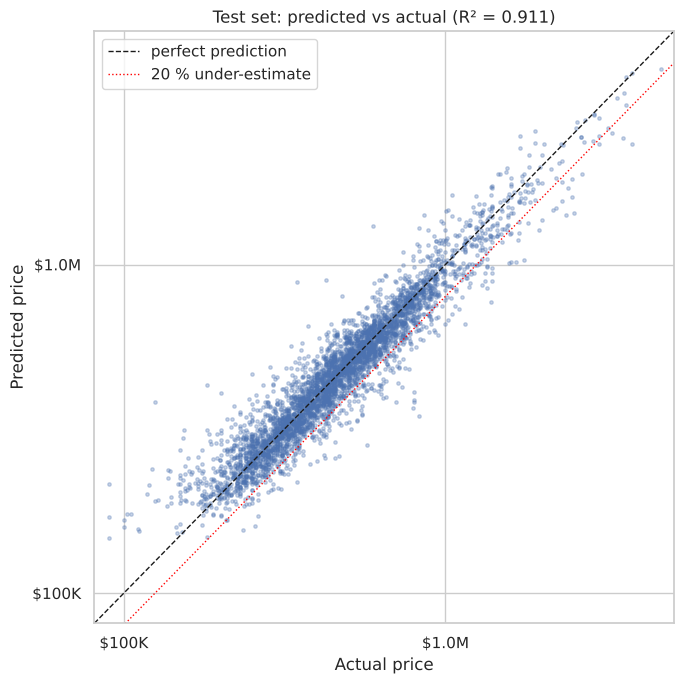

In [15]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(y_test, y_pred, s=6, alpha=0.3)
lims = [min(y_test.min(), y_pred.min()) * 0.9, max(y_test.max(), y_pred.max()) * 1.1]
ax.plot(lims, lims, "k--", lw=1, label="perfect prediction")
ax.plot(lims, [l * 0.8 for l in lims], color="red", lw=1, ls=":", label="20 % under-estimate")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lims); ax.set_ylim(lims)
fmt = plt.FuncFormatter(lambda v, _: f"${v/1e6:.1f}M" if v >= 1e6 else f"${v/1e3:.0f}K")
ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
ax.set_xlabel("Actual price"); ax.set_ylabel("Predicted price")
ax.set_title(f"Test set: predicted vs actual (R² = {test_scores['R²']:.3f})")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "03_predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.2 Where does the model go wrong?

We look at the **percentage error** `(predicted − actual) / actual`: negative = under-estimate (the costly mistake for our agent). We check the overall distribution and the errors per price band, per quality grade and for waterfront houses.

In [16]:
errors = X_test.copy()
errors["actual"] = y_test
errors["predicted"] = y_pred
errors["pct_error"] = 100 * (errors["predicted"] - errors["actual"]) / errors["actual"]
errors["abs_error"] = (errors["predicted"] - errors["actual"]).abs()
errors["price_band"] = pd.cut(errors["actual"], [0, 300e3, 450e3, 650e3, 1e6, np.inf],
                              labels=["< $300K", "$300–450K", "$450–650K", "$650K–1M", "> $1M"])
errors["grade_group"] = pd.cut(errors["grade"], [0, 6, 7, 8, 9, 13],
                               labels=["≤ 6", "7", "8", "9", "≥ 10"])

under_20 = (errors["pct_error"] < -20).mean() * 100
over_20 = (errors["pct_error"] > 20).mean() * 100
print(f"Houses under-estimated by more than 20 %: {under_20:.1f} %")
print(f"Houses over-estimated  by more than 20 %: {over_20:.1f} %")
print(f"Median % error (bias): {errors['pct_error'].median():+.1f} %")

def group_table(col):
    return errors.groupby(col, observed=True).agg(
        houses=("actual", "size"),
        median_price=("actual", "median"),
        MAE=("abs_error", "mean"),
        MAPE=("pct_error", lambda e: e.abs().mean()),
        median_bias_pct=("pct_error", "median"),
    )

by_band = group_table("price_band")
by_grade = group_table("grade_group")
by_water = group_table("waterfront")
display(by_band); display(by_grade); display(by_water)

Houses under-estimated by more than 20 %: 6.2 %
Houses over-estimated  by more than 20 %: 9.5 %
Median % error (bias): -0.5 %


,houses,median_price,MAE,MAPE,median_bias_pct
price_band,,,,,
< $300K,909,"250,000.000","33,373.566",15.161,3.726
$300–450K,1245,"375,000.000","40,293.199",10.642,0.060
$450–650K,1119,"540,000.000","53,167.636",9.794,-0.768
$650K–1M,723,"770,000.000","84,162.381",10.637,-3.252
> $1M,288,"1,350,000.000","227,614.671",14.463,-7.471


,houses,median_price,MAE,MAPE,median_bias_pct
grade_group,,,,,
≤ 6,442,"275,000.000","48,027.697",17.743,-1.534
7,1759,"374,900.000","45,040.733",11.290,-1.535
8,1252,"510,000.000","58,267.393",10.560,0.538
9,506,"715,000.000","75,905.273",9.473,0.365
≥ 10,325,"1,050,000.000","167,953.476",12.708,0.859


,houses,median_price,MAE,MAPE,median_bias_pct
waterfront,,,,,
0,4253,"450,000.000","60,209.354",11.532,-0.497
1,31,"1,155,000.000","333,168.801",25.888,-12.800


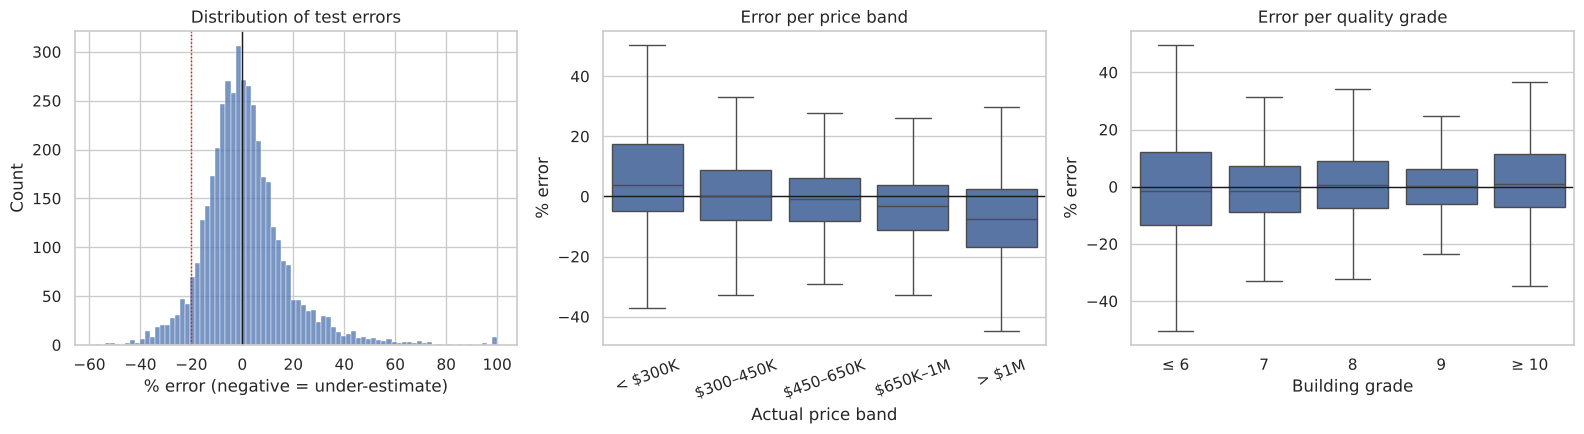

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(errors["pct_error"].clip(-100, 100), bins=80, ax=axes[0])
axes[0].axvline(0, color="k", lw=1)
axes[0].axvline(-20, color="red", ls=":", lw=1)
axes[0].set_xlabel("% error (negative = under-estimate)")
axes[0].set_title("Distribution of test errors")

sns.boxplot(data=errors, x="price_band", y="pct_error", ax=axes[1], showfliers=False)
axes[1].axhline(0, color="k", lw=1)
axes[1].set_xlabel("Actual price band"); axes[1].set_ylabel("% error")
axes[1].set_title("Error per price band")
axes[1].tick_params(axis="x", rotation=20)

sns.boxplot(data=errors, x="grade_group", y="pct_error", ax=axes[2], showfliers=False)
axes[2].axhline(0, color="k", lw=1)
axes[2].set_xlabel("Building grade"); axes[2].set_ylabel("% error")
axes[2].set_title("Error per quality grade")

plt.tight_layout()
plt.savefig(FIG_DIR / "04_errors_by_group.png", dpi=150, bbox_inches="tight")
plt.show()

* **Test MAE $62.2K vs cross-validation $64.0K, R² 0.911.** The test score agrees with cross-validation (slightly better, within noise), so we did not overfit our choices to the folds.
* **For a typical house** the error is small: the median absolute error is $37K and the average error 11.6 % of the price. The overall bias is −0.5 %, so the model is not systematically too high or too low.
* **But the errors are not the same everywhere:**
  * houses under $300K are **over-estimated** (median +3.7 %);
  * houses over $1M are **under-estimated** (median −7.5 %, MAE $228K);
  * the 31 waterfront houses in the test set are under-estimated by 12.8 % (median).

  This is the costly mistake for our agent. The model pulls extreme houses towards the middle of the market (regression to the mean), because there are few luxury and waterfront examples to learn from.
* 6.2 % of houses are under-estimated by more than 20 %, and 9.5 % over-estimated by more than 20 %.
* Per grade, the percentage error is largest for the lowest grades (≤ 6: 17.7 %). These small, cheap houses are often valued for their land, which the model only sees through location.
* **In practice:** for houses the model values above ~$1M, or on the waterfront, the agent should read the prediction as a lower bound.

## 6. Interpretation

### 6.1 Permutation importance (final model)

We shuffle one input column at a time on the test set and measure how much the MAE gets worse. A big increase means the model relies heavily on that column. This works on the original columns, so `zipcode` counts as one feature (not 70 one-hot columns).

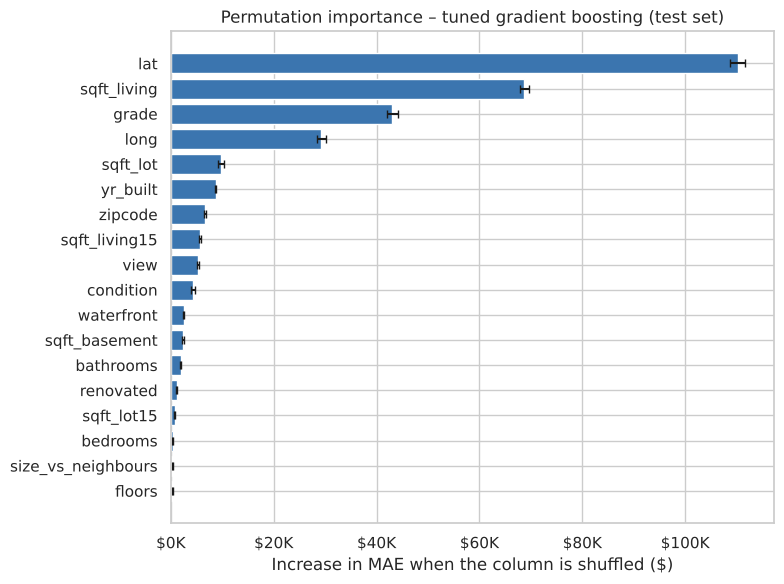

,feature,MAE increase ($),std
7,lat,"110,224.450","1,468.581"
2,sqft_living,"68,705.300",857.809
12,grade,"43,088.268","1,095.186"
8,long,"29,289.725",881.043
3,sqft_lot,"9,807.520",623.039
6,yr_built,"8,748.580",113.365
15,zipcode,"6,586.642",168.310
9,sqft_living15,"5,589.096",190.604
14,view,"5,272.991",143.581
13,condition,"4,368.682",353.727


In [18]:
perm = permutation_importance(final_model, X_test, y_test, scoring="neg_mean_absolute_error",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
importance = (pd.DataFrame({"feature": X_test.columns,
                            "MAE increase ($)": perm.importances_mean,
                            "std": perm.importances_std})
              .sort_values("MAE increase ($)", ascending=True))

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importance["feature"], importance["MAE increase ($)"], xerr=importance["std"], color="#3b75af", capsize=3)
ax.set_xlabel("Increase in MAE when the column is shuffled ($)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))
ax.set_title("Permutation importance – tuned gradient boosting (test set)")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()
importance.sort_values("MAE increase ($)", ascending=False).head(10)

### 6.2 Ridge coefficients (linear model)

Ridge was trained on log(price), so each coefficient reads as a percentage: `exp(coef) − 1` is the price change for **one standard deviation** more of a numeric feature, or for having the flag / zipcode. We show the largest effects.

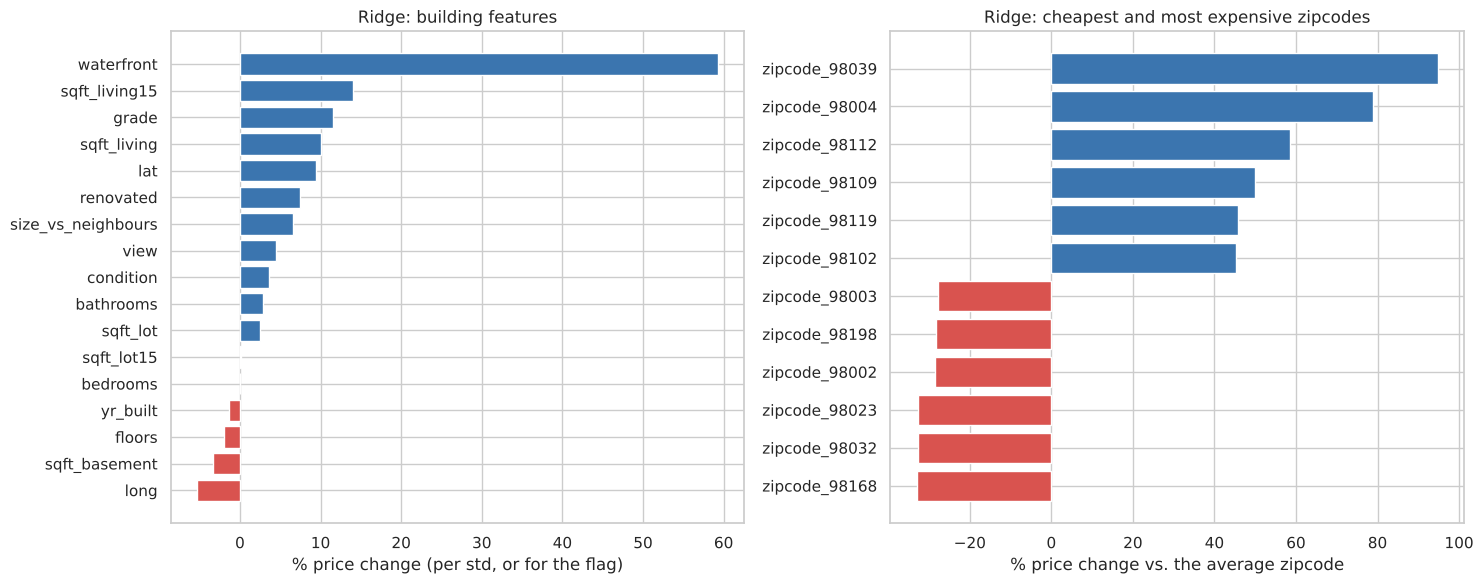

,feature,pct_effect
85,waterfront,59.320
9,sqft_living15,13.999
12,grade,11.594
2,sqft_living,10.047
7,lat,9.470
86,renovated,7.433
11,size_vs_neighbours,6.592
14,view,4.460
13,condition,3.552
1,bathrooms,2.880


In [19]:
ridge_pipe = make_pipeline(Ridge(alpha=1.0)).fit(X_train, y_train)
feature_names = ridge_pipe.named_steps["prep"].get_feature_names_out()
coefs = ridge_pipe.named_steps["model"].regressor_.coef_
coef_df = (pd.DataFrame({"feature": feature_names, "coef": coefs})
           .assign(pct_effect=lambda d: 100 * (np.exp(d["coef"]) - 1),
                   feature=lambda d: d["feature"].str.replace(r"^\w+__", "", regex=True)))

non_zip = coef_df[~coef_df["feature"].str.startswith("zipcode_")].sort_values("pct_effect")
zips = coef_df[coef_df["feature"].str.startswith("zipcode_")].sort_values("pct_effect")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(non_zip["feature"], non_zip["pct_effect"],
             color=np.where(non_zip["pct_effect"] > 0, "#3b75af", "#d9534f"))
axes[0].set_xlabel("% price change (per std, or for the flag)")
axes[0].set_title("Ridge: building features")
top_zips = pd.concat([zips.head(6), zips.tail(6)])
axes[1].barh(top_zips["feature"], top_zips["pct_effect"],
             color=np.where(top_zips["pct_effect"] > 0, "#3b75af", "#d9534f"))
axes[1].set_xlabel("% price change vs. the average zipcode")
axes[1].set_title("Ridge: cheapest and most expensive zipcodes")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_ridge_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()
non_zip.sort_values("pct_effect", ascending=False)[["feature", "pct_effect"]]

### 6.3 Reading the results as designers

* **Location comes first.** Shuffling the latitude makes the MAE $110K worse: by far the most important feature. It is the north–south price divide we saw on the EDA map (expensive Seattle, Bellevue and the lake vs. cheaper south King County). `zipcode` gets only $6.6K, because latitude and longitude already carry the same information: permutation importance splits the credit between correlated features.
* **Then size:** `sqft_living` (+$69K). The number of bedrooms adds nothing once the area is known (≈ 0 in both methods): the market pays for space, not for how it is divided.
* **Build quality beats maintenance.** `grade` is third (+$43K; +11.6 % per standard deviation in Ridge), while `condition` adds only +3.6 %. This matches the EDA: the quality of design and construction matters more than upkeep. In section 7, raising one house from grade 7 to 9 adds about $129K.
* **The neighbourhood matters as much as the house.** `sqft_living15`, the size of the 15 nearest houses and a proxy for how wealthy the area is, has the largest effect of all numeric features in Ridge (+14 %). Being bigger than your neighbours (`size_vs_neighbours`, +6.6 %) helps, but less than being in a street of big houses.
* **Waterfront** has a huge effect (+59 % in Ridge), but a low permutation importance, because only 0.7 % of houses are on the water: a big effect that is rarely used.
* **Negative effects that make sense:** at equal total area, basement space is worth less than above-ground space (`sqft_basement` −3 %). More floors at equal area is slightly negative (−2 %). Newer houses are slightly cheaper at equal everything (−1.3 %), the U-shape from the EDA: old houses sit in expensive central Seattle.
* **Caution:** `sqft_living`, `sqft_living15` and `size_vs_neighbours` are correlated, so the Ridge coefficients should not be read as independent cause-and-effect.
* **Where it fails:** luxury homes, waterfront homes and very cheap small houses (section 5).

## 7. Save and reuse the model

We save the **whole fitted pipeline** (preprocessing + model + log/exp target transform), so a user only needs to pass a table with the raw input columns.

In [20]:
model_path = MODEL_DIR / "model.joblib"
joblib.dump(final_model, model_path)
print(f"Saved to {model_path}  ({model_path.stat().st_size / 1e6:.1f} MB)")
print("Expected input columns:", FEATURES)

Saved to ../models/model.joblib  (1.1 MB)
Expected input columns: ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'sqft_basement', 'yr_built', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'size_vs_neighbours', 'grade', 'condition', 'view', 'zipcode', 'waterfront', 'renovated']


### 7.1 Reload and predict for a hand-made example

An agent is looking at a 1990s family house in Kirkland (zipcode 98033) and wants to know what a renovation that raises the build quality from grade 7 to grade 9 could be worth. Everything else stays the same, so the difference between the two predictions is the model's estimate of the value of better construction quality.

In [21]:
loaded = joblib.load(model_path)

base_house = {
    "bedrooms": 3, "bathrooms": 2.25, "sqft_living": 2000, "sqft_lot": 7500, "floors": 2.0,
    "sqft_basement": 0, "yr_built": 1992, "lat": 47.68, "long": -122.19,
    "sqft_living15": 2100, "sqft_lot15": 7500,
    "grade": 7, "condition": 3, "view": 0, "zipcode": "98033",
    "waterfront": 0, "renovated": 0,
}
option_a = dict(base_house)
option_b = dict(base_house, grade=9, condition=4, renovated=1)

examples = pd.DataFrame([option_a, option_b], index=["A: as is (grade 7)", "B: upgraded (grade 9)"])
examples["size_vs_neighbours"] = examples["sqft_living"] / examples["sqft_living15"]
examples = examples[FEATURES]                       # same column order as training

pred = loaded.predict(examples)
for name, p in zip(examples.index, pred):
    print(f"{name:<24} predicted price: ${p:,.0f}")
print(f"Estimated value of the upgrade: ${pred[1] - pred[0]:,.0f}")

A: as is (grade 7)       predicted price: $658,868
B: upgraded (grade 9)    predicted price: $787,426
Estimated value of the upgrade: $128,559


## 8. Conclusions

### Key findings

* The final model, **tuned gradient boosting on log(price)**, predicts sale prices with a **test MAE of $62.2K** (11.6 % of the price, R² 0.911). The median-price baseline is off by $222K.
* Gradient boosting beats the random forest by ~$5K MAE and Ridge by ~$10K, both real differences. Ridge and random forest are tied in R² (within noise). Tuning gained only $1.4K (within noise).
* **Location (latitude), living area and build quality (grade)** explain most of the price. Bedroom count adds nothing once the area is known, and maintenance (`condition`) matters much less than quality (`grade`).
* The model **under-estimates expensive and waterfront houses** (median −7.5 % above $1M, −12.8 % on the waterfront), which is the costly mistake for our use case.

### Final model and why

`HistGradientBoostingRegressor` (learning rate 0.05, 31 leaves, early stopping) inside a pipeline with one-hot zipcodes, ordinal grade/condition/view, and a log-transformed target.

* **Accuracy:** the best of all models.
* **Speed:** trains in ~3 s and predicts instantly.
* **Size:** the saved file is 1.1 MB.
* **Interpretability:** it is less transparent than Ridge, so we explain it with permutation importance and use Ridge's coefficients as a second opinion.

### Limitations and biases

* **Time and place:** only sales in King County (Washington, USA) between May 2014 and May 2015. Prices have risen a lot since, so absolute predictions are outdated and should only be used for comparisons (e.g. option A vs B). It must not be used for other regions or countries.
* **Building types:** residential houses only. It does not apply to apartments, commercial buildings or empty land. `grade` is King County's own assessor scale, so a user elsewhere cannot fill it in reliably.
* **Value range:** few luxury and waterfront houses, so the model under-estimates them. Do not rely on it above ~$1.5M or for waterfront houses without a manual check.
* **Evaluation:** the split is random, so the same neighbourhoods appear in training and test. The scores measure how well the model interpolates within known areas and the same year, not how it handles a new area or a future market.
* **Bias:** the model learns past market prices, not a "fair" value. Historical price differences between neighbourhoods (which can reflect social and racial segregation) are reproduced. It must not be used for decisions about people, such as lending or insurance.